# 12. Naive Bayes Classifier

**Project** · SMS Spam Detection  
**Problem type** · Classification

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

Multinomial Naive Bayes uses token counts to estimate which class is more likely to have produced a message. For SMS, words can provide evidence for either Spam or Ham. CountVectorizer learns the vocabulary from training text and creates a sparse count matrix.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

The generator creates 960 Ham and 540 Spam messages from 16 templates for each label, varying names, places, times, topics, codes and reward phrases. A synthetic reference number makes each message unique. Both classes use references from the same shuffled sequence. The template family includes the class name and is kept entirely outside the features. Synthetic wording remains simpler than real SMS.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `message_text` | string | SMS text | Raw message used as the only predictive input |
| `template_family` | string | group identifier | Generator template identifier used only to create disjoint splits |
| `sms_label` | string | Ham, Spam | Observed class label |

**Independent variables (X)** · `message_text`.

**Dependent variable (y)** · `sms_label` is the class to predict. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")

from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "12_sms_spam.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 3)


,message_text,template_family,sms_label
0,Limited offer for the cafe shoppers. Text 3343...,spam_05,Spam
1,"Only minutes left to redeem your cash bonus, K...",spam_13,Spam
2,Our group moved the history meeting from the c...,ham_08,Ham
3,"Are you free to help with chemistry at 10:10, ...",ham_07,Ham
4,Our group moved the language meeting from Ceda...,ham_08,Ham
5,Can you bring the phone upgrade we bought for ...,ham_15,Ham
6,Final reminder Isha: your unclaimed travel cre...,spam_04,Spam
7,Can you confirm the chemistry appointment at 1...,ham_13,Ham
8,"Kai, receive a guaranteed phone upgrade. Offer...",spam_10,Spam
9,"Noah, tickets for West Street are ready. Meet ...",ham_05,Ham


message_text       str
template_family    str
sms_label          str
dtype: object

## 3. Mathematical Understanding

Bayes’ theorem gives $P(c\mid x)=P(x\mid c)P(c)/P(x)$, where $c$ is a class, $x$ the observed token-count row, $P(c)$ the prior, $P(x\mid c)$ the likelihood, $P(x)$ the evidence, and $P(c\mid x)$ the posterior. The multinomial model multiplies class-conditional token probabilities, ignoring token order and treating token draws as independent given the label and document length. The multinomial count coefficient is shared across classes and cancels. In log space, compare $\log P(c)+\sum_j x_j\log\theta_{cj}$. Here $j$ identifies a token, $x_j$ is its count and $\theta_{cj}=(N_{cj}+\alpha)/(N_c+\alpha V)$, with token counts $N_{cj}$, total class tokens $N_c$, vocabulary size $V$, and smoothing $\alpha$.

For **“free meeting”**, suppose the three-word vocabulary is free, meeting, reply and the Spam counts are $(6,1,3)$ while Ham counts are $(1,7,2)$. With $\alpha=1$, $P(\text{free}\mid\text{Spam})=7/13$ and $P(\text{meeting}\mid\text{Spam})=2/13$. The corresponding Ham probabilities are $2/13$ and $8/13$. With priors $0.4$ Spam and $0.6$ Ham, the unnormalized scores are $0.4(7/13)(2/13)\approx0.0331$ and $0.6(2/13)(8/13)\approx0.0568$. Divide by their sum to get Spam posterior $0.3684$, so the label is Ham.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/naive_bayes.html#multinomial-naive-bayes)

## 4. Working Principle

Tokenize and count training messages, estimate a prior for each class and smooth its token frequencies. Transform a new message into counts using the learned vocabulary. Sum the log evidence for the observed tokens and choose the class with the largest score.

| Class | Prior | Unnormalized score | Posterior |
| --- | --- | --- | --- |
| Spam | 0.4 | 0.0331 | 0.3684 |
| Ham | 0.6 | 0.0568 | 0.6316 |

**Workflow diagram**

`Raw input` → `Token counts` → `Combines class priors with smoothed token likelihoods` → `Class prediction`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows class balance. Feature plots show variation. The length plot compares how many words appear in messages. Lexical correlation would be high-dimensional and sparse. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "sms_label"
FEATURES = ["message_text"]
NUMERIC = []
CATEGORICAL = []
SEED = 42
LABELS = ["Ham","Spam"]

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   message_text     1500 non-null   str  
 1   template_family  1500 non-null   str  
 2   sms_label        1500 non-null   str  
dtypes: str(3)
memory usage: 159.8 KB


,message_text,template_family,sms_label
0,Limited offer for the cafe shoppers. Text 3343...,spam_05,Spam
1,"Only minutes left to redeem your cash bonus, K...",spam_13,Spam
2,Our group moved the history meeting from the c...,ham_08,Ham
3,"Are you free to help with chemistry at 10:10, ...",ham_07,Ham
4,Our group moved the language meeting from Ceda...,ham_08,Ham


,message_text,template_family,sms_label
1495,Your number won our cash bonus draw. Call 6498...,spam_06,Spam
1496,"Mia, receive a guaranteed travel credit. Offer...",spam_10,Spam
1497,Can you bring the travel credit we bought for ...,ham_15,Ham
1498,"Hi Sam, I left an envelope at the library. Tex...",spam_15,Spam
1499,Limited offer for the station shoppers. Text 2...,spam_05,Spam


,count,unique,top,freq
message_text,1500,1500,Limited offer for the cafe shoppers. Text 3343...,1
template_family,1500,32,ham_08,60
sms_label,1500,2,Ham,960


,Missing,Missing %
message_text,0,0.0
template_family,0,0.0
sms_label,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

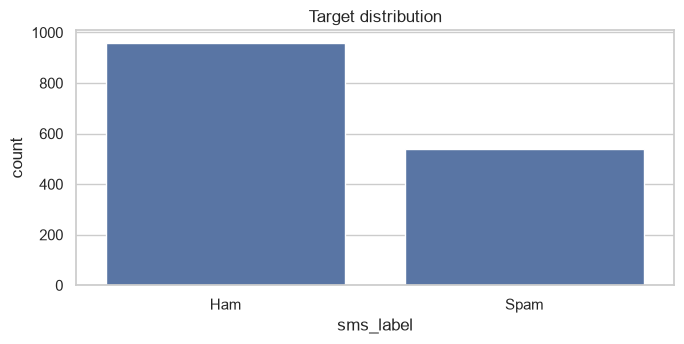

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.countplot(data=df, x=TARGET, order=LABELS, ax=ax)
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

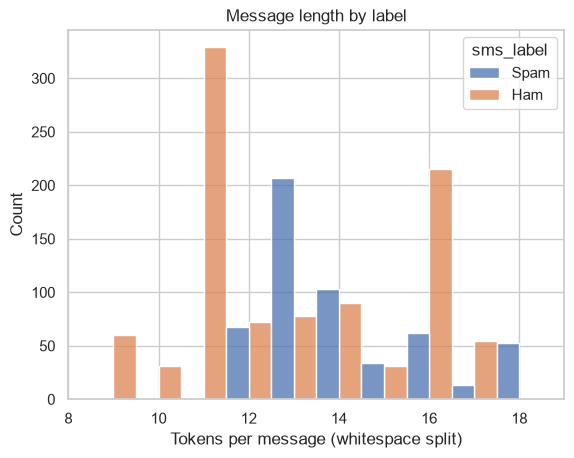

In [5]:
lengths = df.assign(token_count=df["message_text"].str.split().str.len())
fig, ax = plt.subplots()
sns.histplot(lengths, x="token_count", hue=TARGET, multiple="dodge", discrete=True, ax=ax)
ax.set(xlabel="Tokens per message (whitespace split)", title="Message length by label")
plt.show()

## 6. Data Preprocessing

A five-fold `StratifiedGroupKFold` assigns about one fifth of the template families to the holdout while approximately preserving the class balance. The feature vector uses only the text. The family ID contains the label and would leak it as a predictor. Blanks become empty text, yielding zero counts. The tokenizer lowercases text and learns its vocabulary only from the current training partition. Standardization would break the nonnegative count representation.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df["message_text"].fillna("")
label_codes = {'Ham': 0, 'Spam': 1}
y = df[TARGET].map(label_codes)

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

groups = df["template_family"]
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_rows, test_rows = next(splitter.split(X, y, groups))

X_train = X.iloc[train_rows]
X_test = X.iloc[test_rows]
y_train = y.iloc[train_rows]
y_test = y.iloc[test_rows]
train_groups = groups.iloc[train_rows]
test_groups = groups.iloc[test_rows]
print("Test message families:", test_groups.nunique())

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Test message families: 7
Training rows: 1159
Test rows: 341


## 7. Model Implementation

`alpha` adds pseudo-counts so an unseen training token within a class does not force its likelihood to zero. `min_df=2` limits singleton vocabulary entries. `ngram_range=(1, 2)` can include pairs of adjacent words, at a cost in vocabulary size and with overlapping feature evidence.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

estimator = MultinomialNB(alpha=1.0)
model = Pipeline([
    ("features", CountVectorizer(min_df=2)),
    ("model", estimator),
])

### Fit on the training rows

In [9]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"min_df min_df: float in range [0.0, 1.0] or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float, the parameter represents a proportion of documents, integerabsolute counts.This parameter is ignored if vocabulary is not None.",2
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


### Predict on the test rows

In [10]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print("Example predicted class:", LABELS[predictions[0]])

3    Are you free to help with chemistry at 10:10, ...
Name: message_text, dtype: str

Example predicted class: Ham


## 8. Model Evaluation

Let $TP$ count correctly predicted positives, $TN$ correctly predicted negatives, $FP$ false positives, $FN$ false negatives and $N$ all test rows. Higher values indicate better scores, subject to the baseline and the costs of different errors.

| Measure | Formula and interpretation |
| --- | --- |
| Accuracy | $(TP+TN)/N$ for binary outcomes, or the proportion of correct predictions for multiple classes. |
| Precision | $TP/(TP+FP)$. Of the predicted positives, how many really were positive? |
| Recall | $TP/(TP+FN)$. Of the actual positives, how many did the model catch? |
| F1 | $2PR/(P+R)$ for precision $P$ and recall $R$. It is their harmonic mean. |
| ROC-AUC | Area $\int_0^1 \mathrm{TPR}\,d(\mathrm{FPR})$, with $\mathrm{TPR}=TP/(TP+FN)$ and $\mathrm{FPR}=FP/(FP+TN)$. Binary AUC measures the chance of ranking a random positive above a random negative, counting ties as half. Around 0.5 corresponds to chance ranking. |
| Confusion matrix | Entry $(i,j)$ counts rows with actual class $i$ and predicted class $j$. A strong diagonal indicates correct classifications. Examine the off-diagonal cells for costly errors. |
| Classification report | Applies precision, recall and F1 per class. Support counts actual examples per class. Macro averaging weights classes equally, and weighted averaging uses support. |

The positive class is **Spam**. ROC-AUC ranks by its estimated probability. A prior-only classifier gives a baseline. A class with no positive predictions gets zero precision by convention.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

AVERAGE = "binary"
CLASS_IDS = np.arange(len(LABELS))

test_scores = model.predict_proba(X_test)[:, 1]

initial_metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

Accuracy     0.484
Precision    0.365
Recall       1.000
F1           0.534
ROC-AUC      0.792
Name: Test score, dtype: float64

### Compare with a simple baseline

In [12]:
# A baseline knows the training class frequencies and sees no input features.
baseline = DummyClassifier(strategy="prior")
baseline_train = np.zeros((len(y_train), 1))
baseline_test = np.zeros((len(y_test), 1))
baseline.fit(baseline_train, y_train)

baseline_predictions = baseline.predict(baseline_test)
baseline_scores = baseline.predict_proba(baseline_test)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_scores),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.704,0.000,0.0,0.000,0.500
Model,0.484,0.365,1.0,0.534,0.792


### Read the results for each class

In [13]:
print(classification_report(
    y_test, predictions, labels=CLASS_IDS, target_names=LABELS, zero_division=0
))

              precision    recall  f1-score   support

         Ham       1.00      0.27      0.42       240
        Spam       0.36      1.00      0.53       101

    accuracy                           0.48       341
   macro avg       0.68      0.63      0.48       341
weighted avg       0.81      0.48      0.45       341



## 9. Visualizations

Read the confusion matrix by row for each actual class. Off-diagonal cells show the direction and size of confusions. The ROC curve shows the recall and false-positive trade-off across score thresholds.

A positive bar means a token is relatively more likely under Spam than Ham. A negative bar gives Ham evidence. The bars show likelihood ratios from the trained vocabulary. The message prediction also depends on priors and token counts.

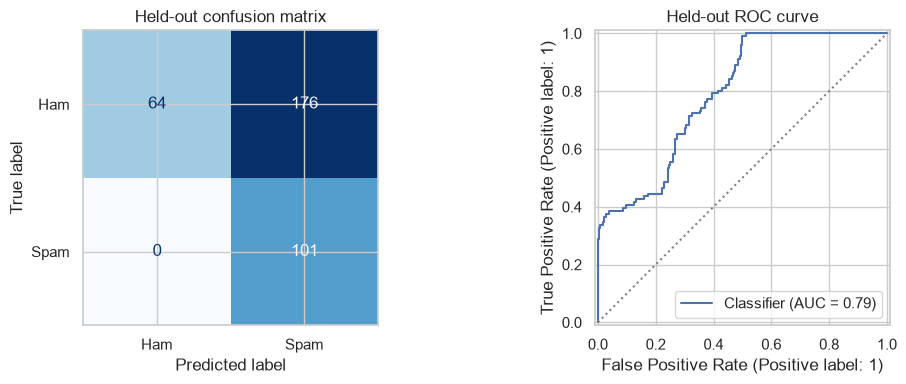

In [14]:
fig, (ax, roc_ax) = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=CLASS_IDS, display_labels=LABELS,
                                        colorbar=False, cmap="Blues", ax=ax)
ax.set_title("Held-out confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_scores, pos_label=1, ax=roc_ax)
roc_ax.plot([0, 1], [0, 1], linestyle=":", color="grey")
roc_ax.set_title("Held-out ROC curve")
fig.tight_layout()
plt.show()

### A closer look at this model

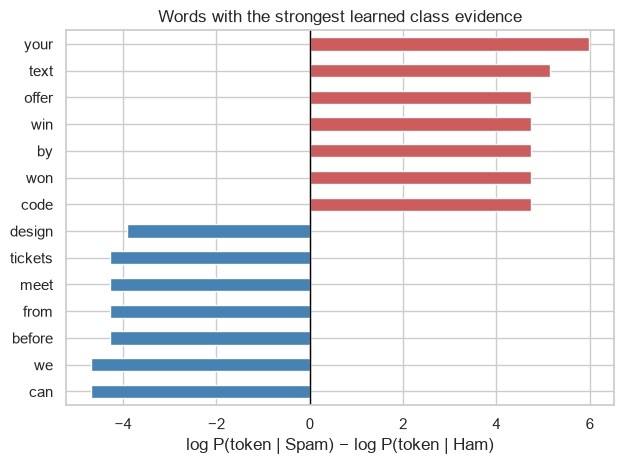

In [15]:
vocabulary = model.named_steps["features"].get_feature_names_out()
token_log_prob = model.named_steps["model"].feature_log_prob_
log_ratio = pd.Series(token_log_prob[1] - token_log_prob[0], index=vocabulary)
extremes = pd.concat([log_ratio.nsmallest(7), log_ratio.nlargest(7)]).sort_values()
ax = extremes.plot.barh(color=np.where(extremes > 0, "indianred", "steelblue"))
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="log P(token | Spam) − log P(token | Ham)", title="Words with the strongest learned class evidence")
plt.tight_layout()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three stratified group folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by positive-class F1. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`alpha` adds pseudo-counts so an unseen training token within a class does not force its likelihood to zero. `min_df=2` limits singleton vocabulary entries. `ngram_range=(1, 2)` can include pairs of adjacent words, at a cost in vocabulary size and with overlapping feature evidence.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {"model__alpha": [0.1, 0.5, 1.0, 3.0], "features__ngram_range": [(1, 1), (1, 2)]}
validation = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="f1", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [17]:
search.fit(X_train, y_train, groups=train_groups)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean CV F1"] = results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean CV F1", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'features__ngram_range': (1, 1), 'model__alpha': 1.0}


,rank_test_score,Mean CV F1,std_test_score,params
3,1,0.960,0.049,"{'features__ngram_range': (1, 1), 'model__alph..."
2,1,0.960,0.049,"{'features__ngram_range': (1, 1), 'model__alph..."
1,3,0.959,0.048,"{'features__ngram_range': (1, 1), 'model__alph..."
0,3,0.959,0.048,"{'features__ngram_range': (1, 1), 'model__alph..."
6,5,0.929,0.049,"{'features__ngram_range': (1, 2), 'model__alph..."


### Compare the models on the test set

In [18]:
tuned_predictions = tuned_model.predict(X_test)
tuned_scores = tuned_model.predict_proba(X_test)[:, 1]

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_scores),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.704,0.000,0.0,0.000,0.500
First model,0.484,0.365,1.0,0.534,0.792
Tuned model,0.484,0.365,1.0,0.534,0.792


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. The result shows the estimated probability of each class. Read those estimates in the context of the synthetic population.

### Enter three new examples

In [19]:
examples = pd.DataFrame([
    ['Asha, can you bring the lab notebook after lunch?'],
    ['Claim your free cash bonus today. Reply WIN immediately.'],
    ['Free tickets for our music practice. Meet me at the cafe.'],
], columns=FEATURES)
display(examples)

,message_text
0,"Asha, can you bring the lab notebook after lunch?"
1,Claim your free cash bonus today. Reply WIN im...
2,Free tickets for our music practice. Meet me a...


### Make predictions

In [20]:
sample_inputs = examples["message_text"]
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Ordinary coordination message","Prize and reply solicitation","Mixed vocabulary containing both free and meeting-related language"]
probabilities = prediction_model.predict_proba(sample_inputs)
example_output["Predicted class"] = np.take(LABELS, sample_predictions)

# Each row contains the class probabilities for one new example.
probability_table = pd.DataFrame(probabilities.round(3), columns=LABELS)
probability_table = probability_table.add_prefix("P(").add_suffix(")")
example_output = pd.concat([example_output, probability_table], axis=1)
display(example_output)

,message_text,Scenario,Predicted class,P(Ham),P(Spam)
0,"Asha, can you bring the lab notebook after lunch?",Ordinary coordination message,Ham,1.0,0.0
1,Claim your free cash bonus today. Reply WIN im...,Prize and reply solicitation,Spam,0.0,1.0
2,Free tickets for our music practice. Meet me a...,Mixed vocabulary containing both free and meet...,Ham,1.0,0.0


## 12. Limitations and Advantages

This model is fast on sparse text and makes token evidence inspectable. Independence often fails for correlated words, and posterior values can be overconfident. Excessive smoothing can underfit. Little smoothing and many rare n-grams can amplify chance patterns. Use it as a small text baseline. For tasks driven by context, sarcasm or long-range meaning, compare models that retain more word order.

## 13. Interview Preparation

### A. 30-second explanation

> I built a spam detector using token counts and Multinomial Naive Bayes. It combines class priors with smoothed token likelihoods, using log scores to avoid multiplying tiny probabilities. I held out entire message families to prevent near-duplicate patterns from crossing the evaluation split.

### B. 90-second technical explanation

> I built a spam detector using token counts and Multinomial Naive Bayes. It combines class priors with smoothed token likelihoods, using log scores to avoid multiplying tiny probabilities. I held out entire message families to prevent near-duplicate patterns from crossing the evaluation split. My target was sms label, and the inputs were message text. Tokenize and count training messages, estimate a prior for each class and smooth its token frequencies. Transform a new message into counts using the learned vocabulary. Sum the log evidence for the observed tokens and choose the class with the largest score. I kept families disjoint and fitted the token vocabulary within each fold. I compared F1 and ROC-AUC with a prior baseline and read the confusion matrix to identify the classes that were easiest to confuse. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What is the prior?** The probability of a class before observing the message.
2. **What is the likelihood?** The probability of the observed token counts conditional on a class.
3. **What is the posterior?** The class probability after observing the message.
4. **Why is the algorithm called naive?** It assumes independent token draws conditional on the class for a fixed message length.
5. **Why add alpha?** It prevents class-specific zero probabilities and shrinks rare estimates.
6. **Why compute log scores?** Sums of logs are more numerically stable than products of small probabilities.
7. **What should MultinomialNB receive?** Nonnegative count-like features rather than standardized values with negative entries.
8. **How does the model handle tokens outside the vocabulary?** CountVectorizer ignores them during transformation.
9. **What happens when none of the message tokens are known?** The class scores reduce to their log priors.
10. **Why hold out message families?** Generalization should include new phrasing rather than repetitions of known templates.

### D. Five scenario questions

1. **A legitimate message says “free meeting.” How should you explain its label?** Combine both likelihood terms and the priors. One token cannot determine the final posterior alone.
2. **Spam now uses new phrases. What do you evaluate?** Use a recent holdout and examine messages with many out-of-vocabulary tokens.
3. **A random split produces 99% accuracy. What would you inspect?** Check for repeated or closely related messages across partitions.
4. **An incorrect spam prediction hides an important message. What would you tune?** Evaluate a higher spam threshold and its precision-recall trade-off on validation folds.
5. **Bigrams raise training accuracy and lower grouped validation F1. What would you choose?** Prefer simpler counts unless further validation supports the bigrams.

### E. Three common mistakes

- Fitting the vocabulary before the split. Put CountVectorizer inside the pipeline.
- Using the template family as an input. Reserve it for grouping.
- Passing centered features to MultinomialNB. Use nonnegative counts.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [21]:
from IPython.display import Markdown

summary = (
    "I built a supervised classification project for sms spam detection using Naive Bayes Classifier. I generated 1,500 synthetic observations and used message text to predict sms label. I used a family-disjoint split and a fold-fitted token vocabulary. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model reached {tuned_metrics['F1']:.3f} F1 for Spam, versus "
    f"{baseline_metrics['F1']:.3f} for the baseline, with ROC-AUC {tuned_metrics['ROC-AUC']:.3f}. "
    "I inspected the tokens with the largest class-conditional likelihood ratios. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised classification project for sms spam detection using Naive Bayes Classifier. I generated 1,500 synthetic observations and used message text to predict sms label. I used a family-disjoint split and a fold-fitted token vocabulary. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model reached 0.534 F1 for Spam, versus 0.000 for the baseline, with ROC-AUC 0.792. I inspected the tokens with the largest class-conditional likelihood ratios. These results apply to the synthetic data and should be validated on representative observations before practical use.